Inisialisasi, Deteksi Path Otomatis, dan Arsitektur Model

In [1]:
from pathlib import Path
from typing import Any, Dict, List, Tuple
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from ucimlrepo import fetch_ucirepo

# --- 1. DETEKSI OTOMATIS AKAR PROYEK AEVIGIL ---
CURRENT_DIR = Path.cwd()
PROJECT_ROOT = (
    CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
)
DATA_DIR = PROJECT_ROOT / "data"
MODEL_DIR = PROJECT_ROOT / "models"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"

for folder in [DATA_DIR, MODEL_DIR, FIG_DIR]:
  folder.mkdir(parents=True, exist_ok=True)

print(f"[Path] Project Root : {PROJECT_ROOT}")
print(f"[Path] Figures Dir  : {FIG_DIR}")

# --- 2. PARAMETER KONFIGURASI EKSPERIMEN ---
RANDOM_SEED: int = 42
BATCH_SIZE: int = 128
NUM_EPOCHS: int = 300
LEARNING_RATE: float = 1e-4
WEIGHT_DECAY: float = 1e-5
MAX_GRAD_NORM: float = 1.0

# Sakelar Revisi Metodologi:
USE_SIGMOID_DECODER: bool = False  # False = Linear Decoder (Revisi), True = Sigmoid (Skripsi Lama)
SPLIT_MODE: str = "disjoint_70_15_15"  # "disjoint_70_15_15" (Revisi) atau "legacy_80_20" (Skripsi Lama)

plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.edgecolor"] = "#333333"
plt.rcParams["axes.linewidth"] = 0.8


def set_deterministic_seed(seed: int = 42) -> torch.device:
  """Mengunci seluruh seed numerik dan memilih perangkat GPU/CPU."""
  np.random.seed(seed)
  torch.manual_seed(seed)
  if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
  dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
  print(f"[Info] Perangkat Aktif: {dev} | Random Seed: {seed}")
  return dev


class AEVigilAutoencoder(nn.Module):
  """Arsitektur Autoencoder Simetris (92 -> 256 -> 128 -> 64 -> 32 -> 64 -> 128 -> 256 -> 92)."""

  def __init__(self, input_dim: int, use_sigmoid: bool = False) -> None:
    super().__init__()
    assert input_dim > 0, f"input_dim harus positif, diterima: {input_dim}"
    self.input_dim = input_dim
    self.use_sigmoid = use_sigmoid

    self.encoder = nn.Sequential(
        nn.Linear(input_dim, 256),
        nn.ReLU(),
        nn.Linear(256, 128),
        nn.ReLU(),
        nn.Linear(128, 64),
        nn.ReLU(),
        nn.Linear(64, 32),
        nn.ReLU(),
    )

    decoder_layers: List[nn.Module] = [
        nn.Linear(32, 64),
        nn.ReLU(),
        nn.Linear(64, 128),
        nn.ReLU(),
        nn.Linear(128, 256),
        nn.ReLU(),
        nn.Linear(256, input_dim),
    ]
    if use_sigmoid:
      decoder_layers.append(nn.Sigmoid())
    self.decoder = nn.Sequential(*decoder_layers)

  def forward(self, x: torch.Tensor) -> torch.Tensor:
    z = self.encoder(x)
    out = self.decoder(z)
    assert out.shape == x.shape, f"Shape mismatch: {out.shape} != {x.shape}"
    return out

  def get_latent(self, x: torch.Tensor) -> torch.Tensor:
    return self.encoder(x)


device = set_deterministic_seed(RANDOM_SEED)

[Path] Project Root : /mnt/c/Users/Lenovo/Code/AEVigil
[Path] Figures Dir  : /mnt/c/Users/Lenovo/Code/AEVigil/reports/figures
[Info] Perangkat Aktif: cuda | Random Seed: 42


Akuisisi Dataset RT-IoT2022, Pra-pemrosesan, dan Ekspor Sampel Demo Render

In [2]:
def load_and_prepare_rt_iot2022(
    split_mode: str = "disjoint_70_15_15",
    seed: int = 42,
) -> Dict[str, Any]:
  """Memuat RT-IoT2022, menyimpan sampel demo Render, One-Hot Encoding, Split, dan Scaling."""
  csv_local_path = DATA_DIR / "RT-IoT2022.csv"
  if csv_local_path.exists():
    print(f"[1/4] Memuat dataset dari berkas lokal: {csv_local_path}")
    df = pd.read_csv(csv_local_path)
  else:
    print("[1/4] Mengunduh dataset RT-IoT2022 dari UCI ML Repository (ID=942)...")
    rt_iot = fetch_ucirepo(id=942)
    df = pd.concat([rt_iot.data.features, rt_iot.data.targets], axis=1)
    df.to_csv(csv_local_path, index=False)
    print(f"      Salinan lokal berhasil disimpan ke: {csv_local_path}")

  if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

  normal_classes = ["Thing_Speak", "MQTT_Publish", "Wipro_bulb"]
  df["is_anomaly"] = df["Attack_type"].apply(
      lambda x: 0 if x in normal_classes else 1
  )

  # Simpan 2.000 sampel terstratifikasi untuk pengujian cepat di aplikasi web Render
  _, df_demo = train_test_split(
      df,
      test_size=2000,
      stratify=df["Attack_type"],
      random_state=seed,
  )
  demo_csv_path = DATA_DIR / "sample_test_iot.csv"
  df_demo.drop(columns=["is_anomaly"]).to_csv(demo_csv_path, index=False)
  print(f"[Info] Sampel uji demo Render (2.000 baris) disimpan ke: {demo_csv_path}")

  # One-Hot Encoding pada kolom kategorikal ('proto', 'service')
  categorical_cols = (
      df.select_dtypes(include=["object"]).columns.drop("Attack_type").tolist()
  )
  df_processed = pd.get_dummies(
      df, columns=categorical_cols, drop_first=True, dtype=float
  )

  feature_cols = [
      c for c in df_processed.columns if c not in ["Attack_type", "is_anomaly"]
  ]
  print(
      f"[2/4] Verifikasi One-Hot Encoding: {df_processed.shape[0]} baris x "
      f"{len(feature_cols)} fitur numerik."
  )
  assert (
      len(feature_cols) == 92
  ), f"Ekspektasi 92 fitur numerik, ditemukan: {len(feature_cols)}"

  X = df_processed[feature_cols]
  y = df_processed["is_anomaly"]
  attack_types = df_processed["Attack_type"]

  X_normal = X[y == 0]
  X_anomaly = X[y == 1]

  if split_mode == "disjoint_70_15_15":
    # Pembagian disjoin murni: 70% Train Normal, 15% Val Normal, 15% Test Normal
    X_train_norm, X_rem_norm = train_test_split(
        X_normal, test_size=0.30, random_state=seed
    )
    X_val_norm, X_test_norm = train_test_split(
        X_rem_norm, test_size=0.50, random_state=seed
    )
  else:
    # Skema lama skripsi: 80% Train Normal, 20% Val Normal (digabung kembali ke Test)
    X_train_norm, X_val_norm = train_test_split(
        X_normal, test_size=0.20, random_state=seed
    )
    X_test_norm = X_val_norm

  X_test = pd.concat([X_test_norm, X_anomaly], axis=0)
  y_test = y.loc[X_test.index].to_numpy()
  attack_test = attack_types.loc[X_test.index].to_numpy()

  # Fit StandardScaler HANYA pada X_train_norm (Mencegah Data Leakage)
  scaler = StandardScaler()
  X_train_scaled = scaler.fit_transform(X_train_norm)
  X_val_scaled = scaler.transform(X_val_norm)
  X_test_scaled = scaler.transform(X_test)

  # Pemeriksaan Asersi Keamanan Data (Bebas NaN & Inf)
  for split_label, mat in [
      ("Train", X_train_scaled),
      ("Val", X_val_scaled),
      ("Test", X_test_scaled),
  ]:
    assert not np.isnan(mat).any(), f"Ditemukan NaN pada himpunan {split_label}"
    assert not np.isinf(mat).any(), f"Ditemukan Inf pada himpunan {split_label}"

  print(f"[3/4] Ringkasan Partisi Data ({split_mode}):")
  print(f"      - Himpunan Latih (Normal)   : {X_train_scaled.shape}")
  print(f"      - Himpunan Validasi (Normal): {X_val_scaled.shape}")
  print(
      f"      - Himpunan Uji (Campuran)   : {X_test_scaled.shape} "
      f"(Normal={np.sum(y_test == 0)}, Anomali={np.sum(y_test == 1)})"
  )

  return {
      "X_train": X_train_scaled,
      "X_val": X_val_scaled,
      "X_test": X_test_scaled,
      "y_test": y_test,
      "attack_test": attack_test,
      "scaler": scaler,
      "feature_cols": feature_cols,
      "categorical_cols": categorical_cols,
  }


data_bundle = load_and_prepare_rt_iot2022(
    split_mode=SPLIT_MODE, seed=RANDOM_SEED
)

[1/4] Mengunduh dataset RT-IoT2022 dari UCI ML Repository (ID=942)...
      Salinan lokal berhasil disimpan ke: /mnt/c/Users/Lenovo/Code/AEVigil/data/RT-IoT2022.csv
[Info] Sampel uji demo Render (2.000 baris) disimpan ke: /mnt/c/Users/Lenovo/Code/AEVigil/data/sample_test_iot.csv
[2/4] Verifikasi One-Hot Encoding: 123117 baris x 92 fitur numerik.


/tmp/ipykernel_2569/1143225922.py:38: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include=["object"]).columns.drop("Attack_type").tolist()


[3/4] Ringkasan Partisi Data (disjoint_70_15_15):
      - Himpunan Latih (Normal)   : (8754, 92)
      - Himpunan Validasi (Normal): (1876, 92)
      - Himpunan Uji (Campuran)   : (112487, 92) (Normal=1877, Anomali=110610)


Pelatihan Model Autoencoder (300 Epoch)

In [3]:
def train_aevigil_model(
    data: Dict[str, Any],
    dev: torch.device,
    use_sigmoid: bool = False,
) -> Tuple[AEVigilAutoencoder, List[float], List[float]]:
  """Melatih Autoencoder selama 300 epoch dan menyimpan bobot validation loss terbaik."""
  train_tensor = torch.FloatTensor(data["X_train"])
  val_tensor = torch.FloatTensor(data["X_val"]).to(dev)

  train_loader = DataLoader(
      TensorDataset(train_tensor, train_tensor),
      batch_size=BATCH_SIZE,
      shuffle=True,
  )

  model = AEVigilAutoencoder(
      input_dim=len(data["feature_cols"]),
      use_sigmoid=use_sigmoid,
  ).to(dev)

  criterion = nn.MSELoss()
  optimizer = optim.Adam(
      model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
  )
  scheduler = optim.lr_scheduler.ReduceLROnPlateau(
      optimizer, mode="min", factor=0.5, patience=10, min_lr=1e-6
  )

  best_val_loss = float("inf")
  best_weights = None
  train_losses: List[float] = []
  val_losses: List[float] = []

  print(
      f"[4/4] Memulai Pelatihan AEVigil ({NUM_EPOCHS} Epoch | "
      f"Sigmoid Output={use_sigmoid})..."
  )

  for epoch in range(NUM_EPOCHS):
    model.train()
    epoch_train_loss = 0.0
    for batch_x, _ in train_loader:
      batch_x = batch_x.to(dev)
      optimizer.zero_grad()
      reconstructed = model(batch_x)
      loss = criterion(reconstructed, batch_x)
      loss.backward()
      nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
      optimizer.step()
      epoch_train_loss += loss.item()

    avg_train_loss = epoch_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    model.eval()
    with torch.no_grad():
      val_recon = model(val_tensor)
      avg_val_loss = criterion(val_recon, val_tensor).item()
    val_losses.append(avg_val_loss)

    scheduler.step(avg_val_loss)

    if avg_val_loss < best_val_loss:
      best_val_loss = avg_val_loss
      best_weights = {
          k: v.cpu().clone() for k, v in model.state_dict().items()
      }

    if (epoch + 1) in [1, 2, 5, 10] or (epoch + 1) % 50 == 0:
      lr_now = optimizer.param_groups[0]["lr"]
      print(
          f"      Epoch [{epoch+1:3d}/{NUM_EPOCHS}] | "
          f"Train Loss: {avg_train_loss:.6f} | Val Loss: {avg_val_loss:.6f} | "
          f"Best Val: {best_val_loss:.6f} | LR: {lr_now:.2e}"
      )

  assert best_weights is not None, "Gagal menyimpan bobot terbaik."
  model.load_state_dict({k: v.to(dev) for k, v in best_weights.items()})

  init_10 = float(np.mean(train_losses[:10]))
  final_10 = float(np.mean(train_losses[-10:]))
  improv_pct = ((init_10 - final_10) / init_10) * 100.0
  print(
      f"\n[Selesai] Best Val Loss: {best_val_loss:.6f} | "
      f"Total Improvement (10 Awal vs 10 Akhir): {improv_pct:.2f}% | "
      f"Final 10-Epoch Std: {np.std(train_losses[-10:]):.6f} | "
      f"Final 10-Epoch Var: {np.var(train_losses[-10:]):.8f}"
  )
  return model, train_losses, val_losses


model, train_losses, val_losses = train_aevigil_model(
    data_bundle, device, use_sigmoid=USE_SIGMOID_DECODER
)

[4/4] Memulai Pelatihan AEVigil (300 Epoch | Sigmoid Output=False)...
      Epoch [  1/300] | Train Loss: 0.956195 | Val Loss: 0.776935 | Best Val: 0.776935 | LR: 1.00e-04
      Epoch [  2/300] | Train Loss: 0.902775 | Val Loss: 0.623432 | Best Val: 0.623432 | LR: 1.00e-04
      Epoch [  5/300] | Train Loss: 0.544290 | Val Loss: 0.369683 | Best Val: 0.369683 | LR: 1.00e-04
      Epoch [ 10/300] | Train Loss: 0.454141 | Val Loss: 0.288269 | Best Val: 0.288269 | LR: 1.00e-04
      Epoch [ 50/300] | Train Loss: 0.139089 | Val Loss: 0.089341 | Best Val: 0.089341 | LR: 1.00e-04
      Epoch [100/300] | Train Loss: 0.036957 | Val Loss: 0.041964 | Best Val: 0.041326 | LR: 1.00e-04
      Epoch [150/300] | Train Loss: 0.023703 | Val Loss: 0.034418 | Best Val: 0.033911 | LR: 1.00e-04
      Epoch [200/300] | Train Loss: 0.016025 | Val Loss: 0.031608 | Best Val: 0.030041 | LR: 1.00e-04
      Epoch [250/300] | Train Loss: 0.010856 | Val Loss: 0.027594 | Best Val: 0.027346 | LR: 5.00e-05
      Epoch 

Evaluasi Semua Tabel, Bundel Artefak Render, & Ekspor Grafik 300 DPI


================ TABEL 2: ANALISIS AMBANG BATAS VALIDASI ================
            Metode  Nilai Threshold  Proporsi Normal > Threshold  Estimasi FPR Validasi (%)
  Mean + 2*Std Dev         0.552956                       0.0107                       1.07
   Persentil ke-95         0.010709                       0.0501                       5.01
   Persentil ke-97         0.039336                       0.0304                       3.04
   Persentil ke-99         0.610649                       0.0101                       1.01
IQR (Q3 + 1.5*IQR)         0.002220                       0.1397                      13.97

[Info] Baseline Confusion Matrix (TN, FP, FN, TP): [1820, 57, 2448, 108162] | ROC-AUC: 0.9960

================ TABEL 4: 12 KOMBINASI VRE ================
Skema Ambang Strategi Agregasi  Accuracy  F1 Normal  F1 Anomali
  Percentile               any    0.9965     0.8911      0.9982
  Percentile          majority    0.9194     0.2879      0.9573
  Percentile             

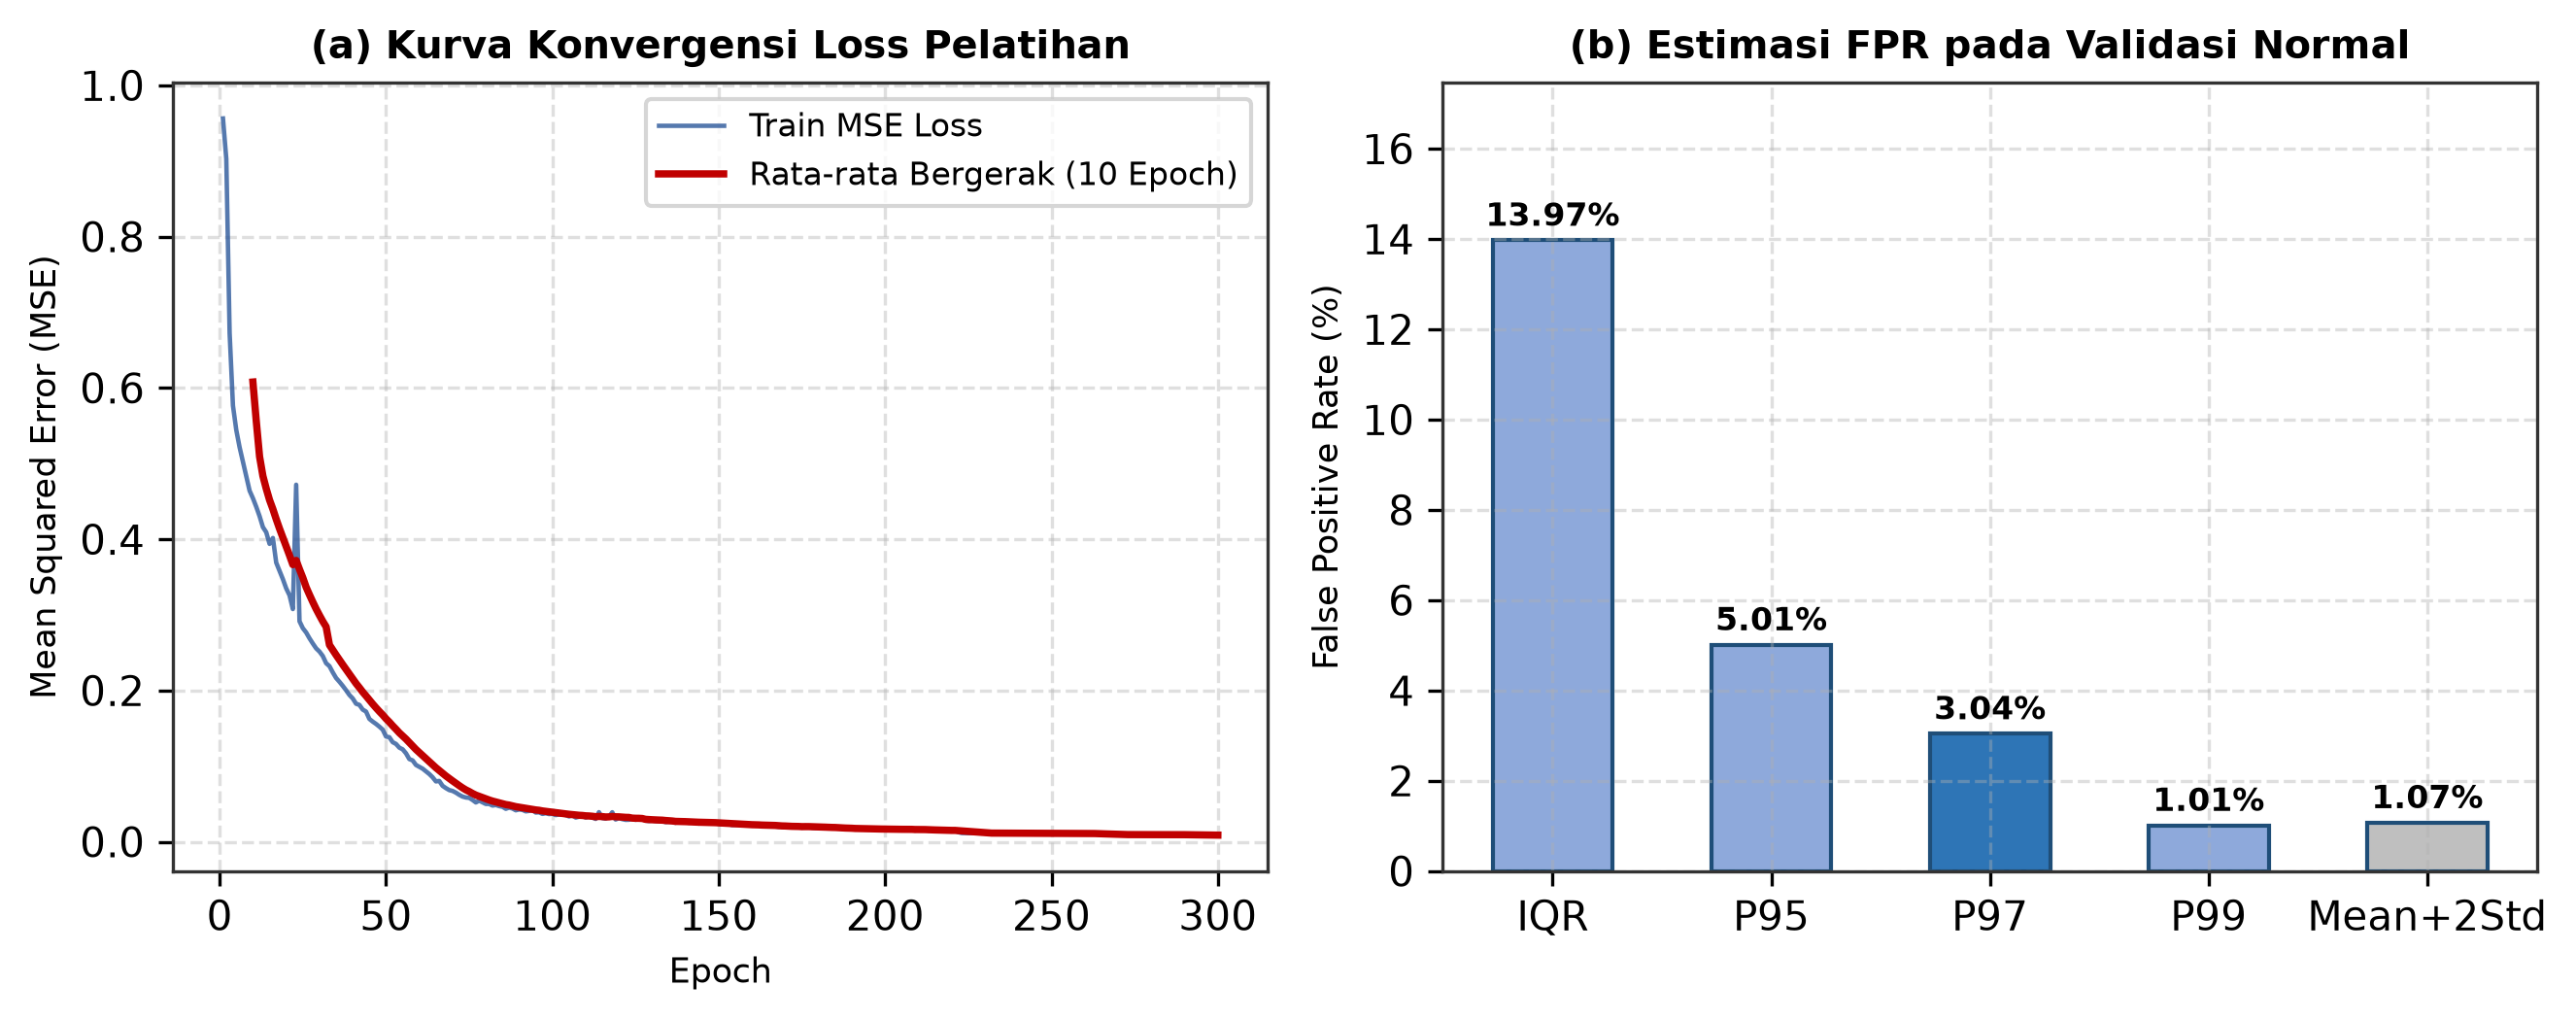

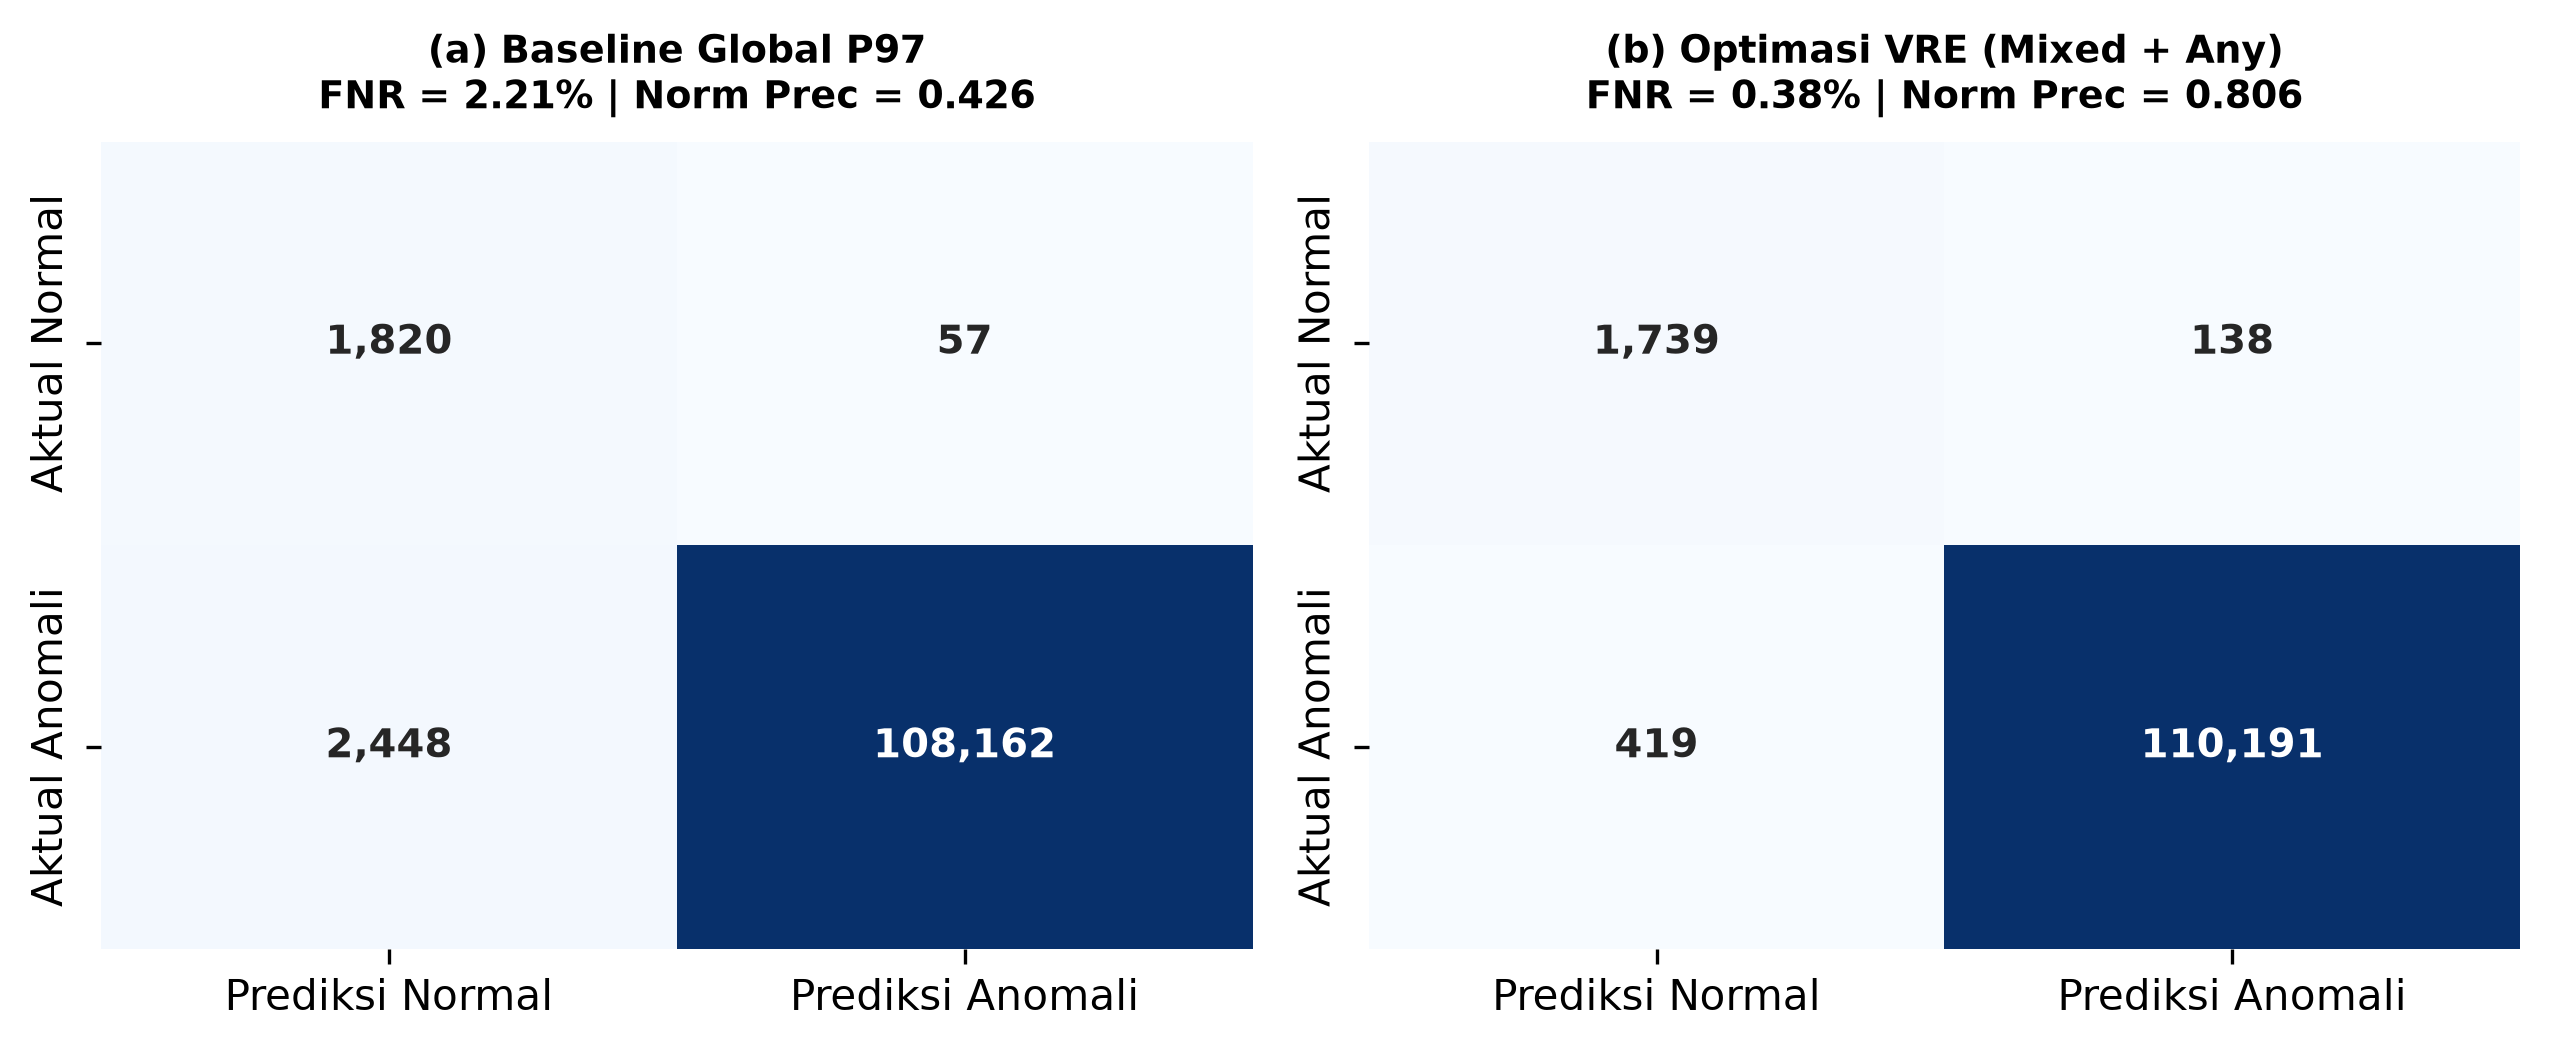

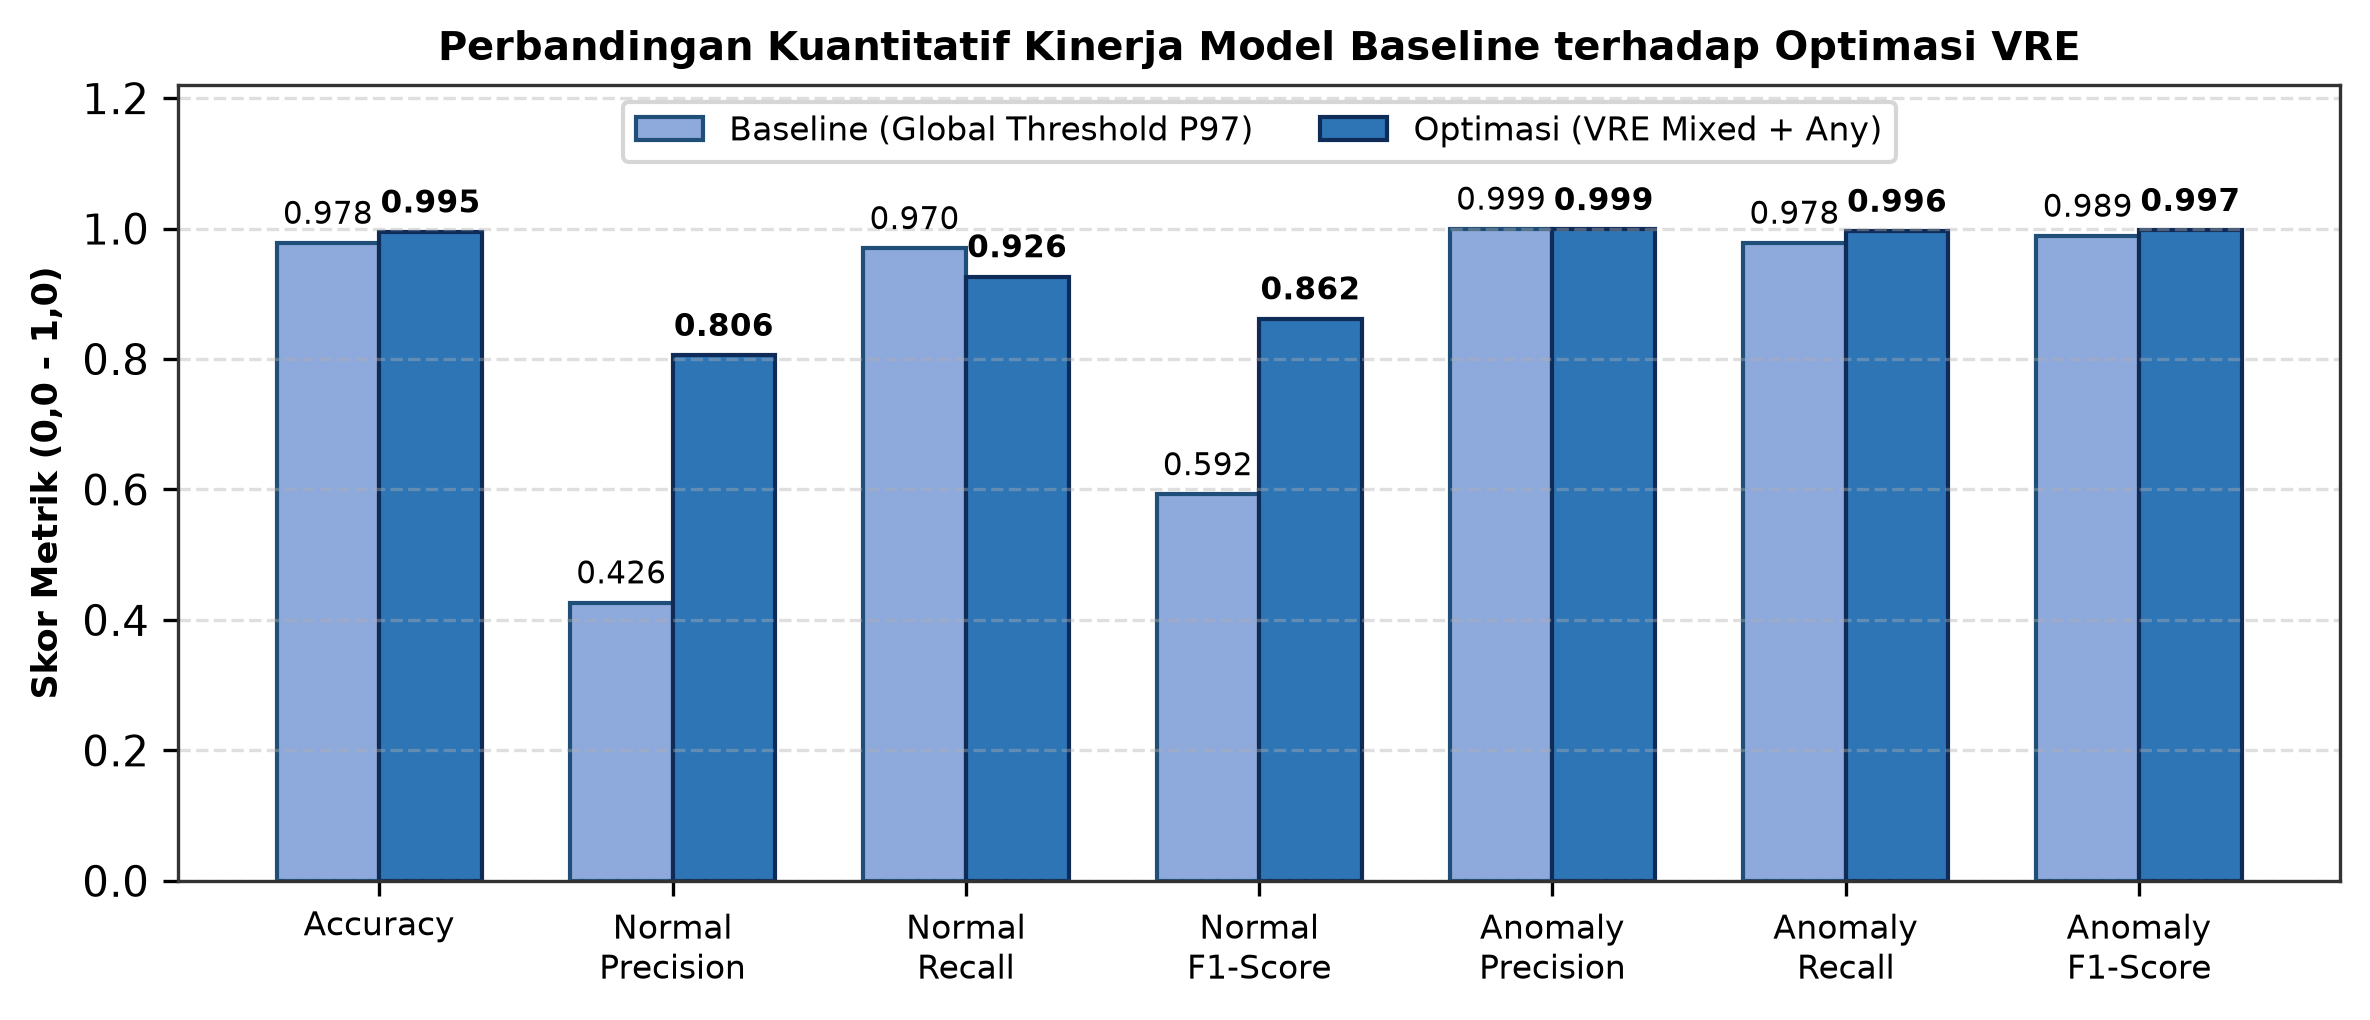

In [4]:
def evaluate_and_export_journal_assets(
    model: AEVigilAutoencoder,
    data: Dict[str, Any],
    train_losses: List[float],
    dev: torch.device,
) -> Dict[str, Any]:
  """Mencetak Tabel 2, 4, 5, 6, & menyimpan bundel Render, serta grafik 300 DPI."""
  model.eval()
  val_tensor = torch.FloatTensor(data["X_val"]).to(dev)
  test_tensor = torch.FloatTensor(data["X_test"]).to(dev)
  y_test = data["y_test"]
  attack_test = data["attack_test"]

  with torch.no_grad():
    val_recon = model(val_tensor)
    test_recon = model(test_tensor)

    # 1. Galat Skalar Global (MSE / L2)
    val_mse = torch.mean((val_recon - val_tensor) ** 2, dim=1).cpu().numpy()
    test_mse = torch.mean((test_recon - test_tensor) ** 2, dim=1).cpu().numpy()

    # 2. Galat Vektor Per-Fitur (Absolute / L1)
    val_l1 = torch.abs(val_tensor - val_recon).cpu().numpy()
    test_l1 = torch.abs(test_tensor - test_recon).cpu().numpy()

  # --- TABEL 2: ANALISIS AMBANG BATAS GLOBAL PADA DATA VALIDASI ---
  q1, q3 = np.percentile(val_mse, [25, 75])
  global_candidates = {
      "Mean + 2*Std Dev": float(np.mean(val_mse) + 2.0 * np.std(val_mse)),
      "Persentil ke-95": float(np.percentile(val_mse, 95)),
      "Persentil ke-97": float(np.percentile(val_mse, 97)),
      "Persentil ke-99": float(np.percentile(val_mse, 99)),
      "IQR (Q3 + 1.5*IQR)": float(q3 + 1.5 * (q3 - q1)),
  }

  rows_t2 = []
  for name, th_val in global_candidates.items():
    prop_exceed = float(np.mean(val_mse > th_val))
    rows_t2.append({
        "Metode": name,
        "Nilai Threshold": round(th_val, 6),
        "Proporsi Normal > Threshold": round(prop_exceed, 4),
        "Estimasi FPR Validasi (%)": round(prop_exceed * 100.0, 2),
    })
  df_table2 = pd.DataFrame(rows_t2)
  print("\n================ TABEL 2: ANALISIS AMBANG BATAS VALIDASI ================")
  print(df_table2.to_string(index=False))

  # --- EVALUASI MODEL BASELINE (GLOBAL THRESHOLD P97) ---
  th_global_p97 = global_candidates["Persentil ke-97"]
  pred_baseline = (test_mse > th_global_p97).astype(int)
  cm_base = confusion_matrix(y_test, pred_baseline)
  roc_auc_val = float(roc_auc_score(y_test, test_mse))
  print(f"\n[Info] Baseline Confusion Matrix (TN, FP, FN, TP): {cm_base.ravel().tolist()} | ROC-AUC: {roc_auc_val:.4f}")

  # --- TABEL 4: PENGUJIAN 12 KOMBINASI VRE ---
  vre_thresholds = {
      "Percentile": np.percentile(val_l1, 97, axis=0),
      "Statistical": np.mean(val_l1, axis=0) + 2.5 * np.std(val_l1, axis=0),
  }
  vre_thresholds["Mixed"] = np.maximum(
      vre_thresholds["Percentile"], vre_thresholds["Statistical"]
  )

  feat_std = np.std(val_l1, axis=0)
  inv_std = 1.0 / (feat_std + 1e-8)
  feature_weights = inv_std / np.sum(inv_std)
  count_min = max(1, int(0.10 * val_l1.shape[1]))

  rows_t4 = []
  best_vre_pred = None
  for scheme_name, th_vec in vre_thresholds.items():
    exceed_mask = test_l1 > th_vec
    for agg in ["any", "majority", "count", "weighted"]:
      if agg == "any":
        pred = np.any(exceed_mask, axis=1).astype(int)
      elif agg == "majority":
        pred = (np.mean(exceed_mask, axis=1) > 0.50).astype(int)
      elif agg == "count":
        pred = (np.sum(exceed_mask, axis=1) >= count_min).astype(int)
      else:
        pred = (np.sum(exceed_mask * feature_weights, axis=1) >= 0.10).astype(
            int
        )

      rows_t4.append({
          "Skema Ambang": scheme_name,
          "Strategi Agregasi": agg,
          "Accuracy": round(accuracy_score(y_test, pred), 4),
          "F1 Normal": round(
              f1_score(y_test, pred, pos_label=0, zero_division=0), 4
          ),
          "F1 Anomali": round(
              f1_score(y_test, pred, pos_label=1, zero_division=0), 4
          ),
      })
      if scheme_name == "Mixed" and agg == "any":
        best_vre_pred = pred

  df_table4 = pd.DataFrame(rows_t4)
  print("\n================ TABEL 4: 12 KOMBINASI VRE ================")
  print(df_table4.to_string(index=False))

  assert best_vre_pred is not None
  cm_vre = confusion_matrix(y_test, best_vre_pred)
  print(f"\n[Info] VRE (Mixed+Any) Confusion Matrix (TN, FP, FN, TP): {cm_vre.ravel().tolist()}")

  # --- TABEL 5: PERBANDINGAN BASELINE VS OPTIMASI VRE ---
  def compute_summary_metrics(y_true: np.ndarray, y_hat: np.ndarray) -> Dict[str, float]:
    tn, fp, fn, tp = confusion_matrix(y_true, y_hat).ravel()
    return {
        "Accuracy": float(accuracy_score(y_true, y_hat)),
        "Balanced Accuracy": float(balanced_accuracy_score(y_true, y_hat)),
        "Normal Precision": float(precision_score(y_true, y_hat, pos_label=0, zero_division=0)),
        "Normal Recall (TNR)": float(recall_score(y_true, y_hat, pos_label=0, zero_division=0)),
        "Normal F1-Score": float(f1_score(y_true, y_hat, pos_label=0, zero_division=0)),
        "Anomaly Precision": float(precision_score(y_true, y_hat, pos_label=1, zero_division=0)),
        "Anomaly Recall (TPR)": float(recall_score(y_true, y_hat, pos_label=1, zero_division=0)),
        "Anomaly F1-Score": float(f1_score(y_true, y_hat, pos_label=1, zero_division=0)),
        "FNR": float(fn / (fn + tp)),
        "FPR": float(fp / (fp + tn)),
    }

  m_base = compute_summary_metrics(y_test, pred_baseline)
  m_vre = compute_summary_metrics(y_test, best_vre_pred)

  rows_t5 = []
  for k in m_base:
    b_val = m_base[k]
    v_val = m_vre[k]
    pct_change = ((v_val - b_val) / b_val * 100.0) if b_val > 0 else 0.0
    rows_t5.append({
        "Metrik": k,
        "Baseline (Global P97)": round(b_val, 4),
        "Optimasi (VRE Mixed+Any)": round(v_val, 4),
        "Perubahan (%)": f"{pct_change:+.1f}%",
    })
  df_table5 = pd.DataFrame(rows_t5)
  print("\n================ TABEL 5: BASELINE VS OPTIMASI VRE ================")
  print(df_table5.to_string(index=False))

  # --- TABEL 6: DISTRIBUSI FALSE NEGATIVE SPESIFIK ---
  fn_mask = (y_test == 1) & (best_vre_pred == 0)
  fn_counts = pd.Series(attack_test[fn_mask]).value_counts()
  total_anom_counts = pd.Series(attack_test[y_test == 1]).value_counts()

  rows_t6 = []
  for att_name, tot_c in total_anom_counts.items():
    fn_c = int(fn_counts.get(att_name, 0))
    tp_c = int(tot_c - fn_c)
    rows_t6.append({
        "Attack_type": att_name,
        "Total Uji": int(tot_c),
        "Terdeteksi (TP)": tp_c,
        "Lolos (FN)": fn_c,
        "Detection Rate (%)": round((tp_c / tot_c) * 100.0, 2),
    })
  df_table6 = pd.DataFrame(rows_t6)
  print("\n================ TABEL 6: ANALISIS ERROR SPESIFIK (VRE) ================")
  print(df_table6.to_string(index=False))

  # --- SIMPAN BUNDEL ARTEFAK TUNGGAL UNTUK RENDER ---
  bundle_path = MODEL_DIR / "aevigil_bundle.joblib"
  artifact_payload = {
      "model_state_dict": {k: v.cpu() for k, v in model.state_dict().items()},
      "input_dim": len(data["feature_cols"]),
      "use_sigmoid": model.use_sigmoid,
      "split_mode": SPLIT_MODE,
      "scaler": data["scaler"],
      "feature_cols": data["feature_cols"],
      "categorical_cols": data["categorical_cols"],
      "global_candidates": global_candidates,
      "val_mse_errors": val_mse,
      "vre_thresholds": vre_thresholds,
      "feature_weights": feature_weights,
  }
  joblib.dump(artifact_payload, bundle_path, compress=3)
  print(f"\n[Artefak] Bundel lengkap untuk Render disimpan ke: {bundle_path}")

  # --- EKSPOR GRAFIK 300 DPI ---
  # Grafik 2: Konvergensi Loss & Estimasi FPR Validasi
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.0, 3.6), dpi=300)
  ep_range = np.arange(1, len(train_losses) + 1)
  ax1.plot(ep_range, train_losses, color="#2B579A", lw=1.1, alpha=0.8, label="Train MSE Loss")
  if len(train_losses) >= 10:
    mov_avg = np.convolve(train_losses, np.ones(10) / 10, mode="valid")
    ax1.plot(ep_range[9:], mov_avg, color="#C00000", lw=1.8, label="Rata-rata Bergerak (10 Epoch)")
  ax1.set_title("(a) Kurva Konvergensi Loss Pelatihan", fontsize=9.5, fontweight="bold")
  ax1.set_xlabel("Epoch", fontsize=8.5)
  ax1.set_ylabel("Mean Squared Error (MSE)", fontsize=8.5)
  ax1.grid(True, linestyle="--", alpha=0.4)
  ax1.legend(fontsize=8)

  m_labels = ["IQR", "P95", "P97", "P99", "Mean+2Std"]
  fpr_list = [
      df_table2.loc[df_table2["Metode"] == "IQR (Q3 + 1.5*IQR)", "Estimasi FPR Validasi (%)"].values[0],
      df_table2.loc[df_table2["Metode"] == "Persentil ke-95", "Estimasi FPR Validasi (%)"].values[0],
      df_table2.loc[df_table2["Metode"] == "Persentil ke-97", "Estimasi FPR Validasi (%)"].values[0],
      df_table2.loc[df_table2["Metode"] == "Persentil ke-99", "Estimasi FPR Validasi (%)"].values[0],
      df_table2.loc[df_table2["Metode"] == "Mean + 2*Std Dev", "Estimasi FPR Validasi (%)"].values[0],
  ]
  bars = ax2.bar(m_labels, fpr_list, color=["#8EA9DB", "#8EA9DB", "#2E75B6", "#8EA9DB", "#BFBFBF"], edgecolor="#1F4E78", width=0.55)
  for bar, v in zip(bars, fpr_list):
    ax2.text(bar.get_x() + bar.get_width() / 2, v + 0.15, f"{v:.2f}%", ha="center", va="bottom", fontsize=8, fontweight="bold")
  ax2.set_ylim(0, max(fpr_list) * 1.25)
  ax2.set_title("(b) Estimasi FPR pada Validasi Normal", fontsize=9.5, fontweight="bold")
  ax2.set_ylabel("False Positive Rate (%)", fontsize=8.5)
  ax2.grid(True, linestyle="--", alpha=0.4)
  plt.tight_layout()
  plt.savefig(FIG_DIR / "fig2_training_and_fpr.png", dpi=300, bbox_inches="tight")
  plt.show()

  # Grafik 3: Perbandingan Confusion Matrix Baseline vs Optimasi VRE
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.6, 3.6), dpi=300)
  for ax, cm_mat, title_str in [
      (ax1, cm_base, f"(a) Baseline Global P97\nFNR = {m_base['FNR']*100:.2f}% | Norm Prec = {m_base['Normal Precision']:.3f}"),
      (ax2, cm_vre, f"(b) Optimasi VRE (Mixed + Any)\nFNR = {m_vre['FNR']*100:.2f}% | Norm Prec = {m_vre['Normal Precision']:.3f}"),
  ]:
    sns.heatmap(
        cm_mat,
        annot=True,
        fmt=",d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Prediksi Normal", "Prediksi Anomali"],
        yticklabels=["Aktual Normal", "Aktual Anomali"],
        ax=ax,
        annot_kws={"size": 9.5, "weight": "bold"},
    )
    ax.set_title(title_str, fontsize=9, fontweight="bold", pad=8)
  plt.tight_layout()
  plt.savefig(FIG_DIR / "fig3_confusion_matrices.png", dpi=300, bbox_inches="tight")
  plt.show()

  # Grafik 4: Diagram Batang Perbandingan Metrik Kinerja
  fig, ax = plt.subplots(figsize=(8.0, 3.5), dpi=300)
  m_keys = ["Accuracy", "Normal Precision", "Normal Recall (TNR)", "Normal F1-Score", "Anomaly Precision", "Anomaly Recall (TPR)", "Anomaly F1-Score"]
  m_short = ["Accuracy", "Normal\nPrecision", "Normal\nRecall", "Normal\nF1-Score", "Anomaly\nPrecision", "Anomaly\nRecall", "Anomaly\nF1-Score"]
  b_vals = [m_base[k] for k in m_keys]
  v_vals = [m_vre[k] for k in m_keys]
  x_pos = np.arange(len(m_keys))
  w = 0.35
  r1 = ax.bar(x_pos - w / 2, b_vals, w, label="Baseline (Global Threshold P97)", color="#8EA9DB", edgecolor="#1F4E78")
  r2 = ax.bar(x_pos + w / 2, v_vals, w, label="Optimasi (VRE Mixed + Any)", color="#2E75B6", edgecolor="#0F2C59")
  for r in r1:
    h = r.get_height()
    ax.text(r.get_x() + r.get_width() / 2, h + 0.018, f"{h:.3f}", ha="center", va="bottom", fontsize=7.5)
  for r in r2:
    h = r.get_height()
    ax.text(r.get_x() + r.get_width() / 2, h + 0.018, f"{h:.3f}", ha="center", va="bottom", fontsize=7.5, fontweight="bold")
  ax.set_ylim(0, 1.22)
  ax.set_xticks(x_pos)
  ax.set_xticklabels(m_short, fontsize=8)
  ax.set_ylabel("Skor Metrik (0,0 - 1,0)", fontsize=8.5, fontweight="bold")
  ax.set_title("Perbandingan Kuantitatif Kinerja Model Baseline terhadap Optimasi VRE", fontsize=9.5, fontweight="bold")
  ax.legend(loc="upper center", ncol=2, fontsize=8)
  ax.grid(axis="y", linestyle="--", alpha=0.4)
  plt.tight_layout()
  plt.savefig(FIG_DIR / "fig4_metrics_comparison.png", dpi=300, bbox_inches="tight")
  plt.show()

  return {
      "table2": df_table2,
      "table4": df_table4,
      "table5": df_table5,
      "table6": df_table6,
  }


results = evaluate_and_export_journal_assets(
    model, data_bundle, train_losses, device
)

Visualisasi Ruang Laten t-SNE (300 DPI)

[t-SNE] Memproyeksikan 2500 sampel ruang laten (32D -> 2D)...


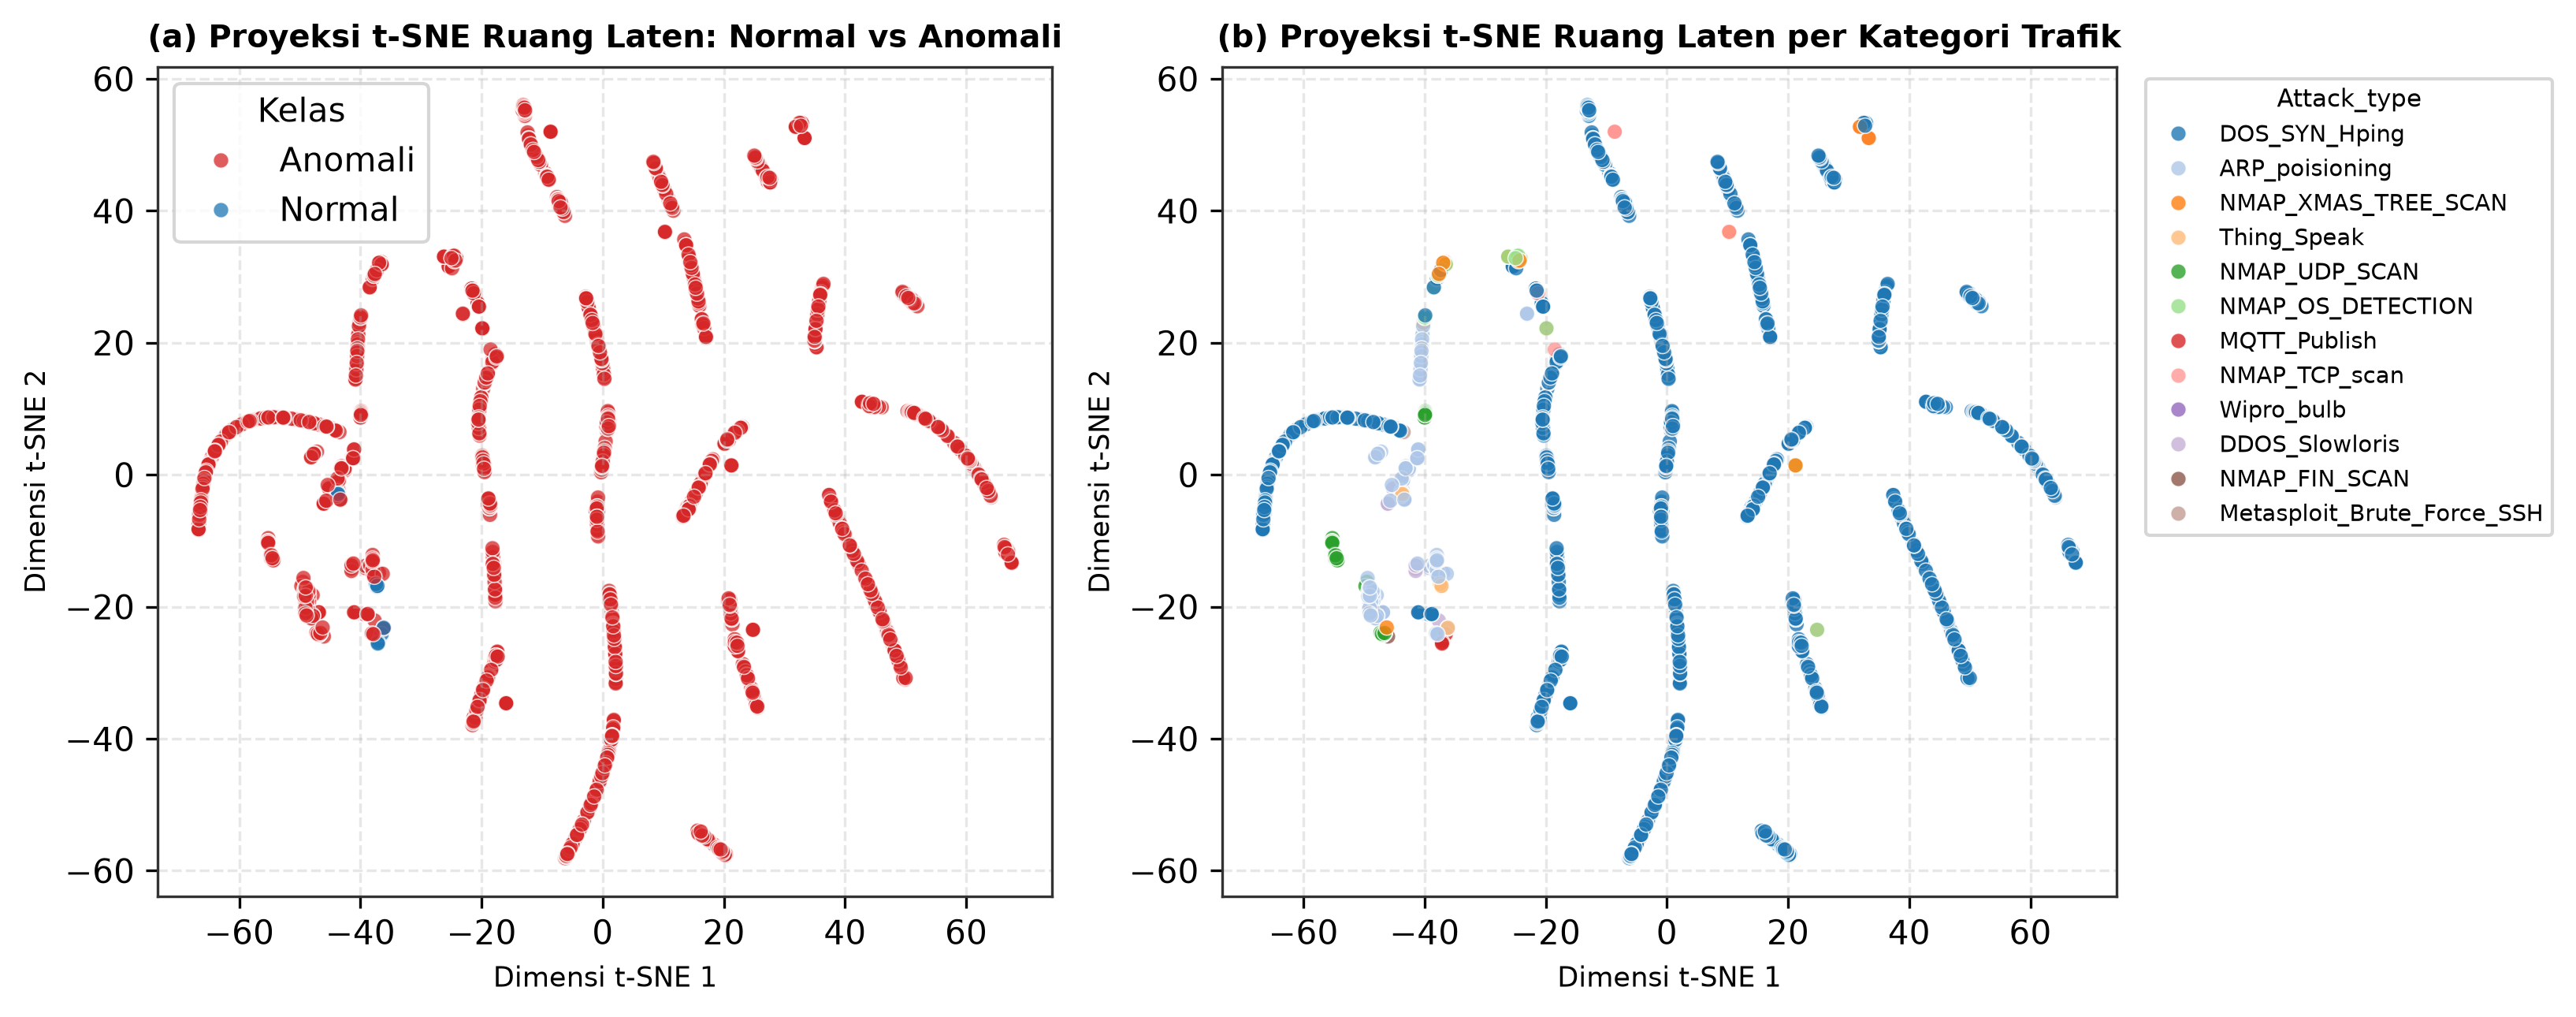

[Selesai] Grafik t-SNE disimpan ke: /mnt/c/Users/Lenovo/Code/AEVigil/reports/figures/fig5_tsne_latent.png


In [5]:
def generate_tsne_journal_figure(
    model: AEVigilAutoencoder,
    data: Dict[str, Any],
    dev: torch.device,
    sample_size: int = 2500,
    perplexity: int = 30,
) -> None:
  """Mengekstrak representasi laten 32-dimensi dan membuat plot t-SNE 2 panel (300 DPI)."""
  model.eval()
  y_test = data["y_test"]
  attack_test = data["attack_test"]

  idx_all = np.arange(len(y_test))
  _, idx_sub = train_test_split(
      idx_all,
      test_size=sample_size,
      stratify=attack_test,
      random_state=RANDOM_SEED,
  )

  x_sub = torch.FloatTensor(data["X_test"][idx_sub]).to(dev)
  with torch.no_grad():
    latent_vecs = model.get_latent(x_sub).cpu().numpy()

  print(f"[t-SNE] Memproyeksikan {sample_size} sampel ruang laten (32D -> 2D)...")
  tsne_coords = TSNE(
      n_components=2,
      perplexity=perplexity,
      max_iter=1000,
      random_state=RANDOM_SEED,
  ).fit_transform(latent_vecs)

  df_tsne = pd.DataFrame({
      "tsne_1": tsne_coords[:, 0],
      "tsne_2": tsne_coords[:, 1],
      "Kelas": np.where(y_test[idx_sub] == 0, "Normal", "Anomali"),
      "Jenis Trafik": attack_test[idx_sub],
  })

  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.0, 4.4), dpi=300)

  sns.scatterplot(
      data=df_tsne,
      x="tsne_1",
      y="tsne_2",
      hue="Kelas",
      palette={"Normal": "#1F77B4", "Anomali": "#D62728"},
      alpha=0.75,
      s=22,
      ax=ax1,
  )
  ax1.set_title("(a) Proyeksi t-SNE Ruang Laten: Normal vs Anomali", fontsize=9.5, fontweight="bold")
  ax1.set_xlabel("Dimensi t-SNE 1", fontsize=8.5)
  ax1.set_ylabel("Dimensi t-SNE 2", fontsize=8.5)
  ax1.grid(True, linestyle="--", alpha=0.3)

  sns.scatterplot(
      data=df_tsne,
      x="tsne_1",
      y="tsne_2",
      hue="Jenis Trafik",
      palette="tab20",
      alpha=0.8,
      s=22,
      ax=ax2,
  )
  ax2.set_title("(b) Proyeksi t-SNE Ruang Laten per Kategori Trafik", fontsize=9.5, fontweight="bold")
  ax2.set_xlabel("Dimensi t-SNE 1", fontsize=8.5)
  ax2.set_ylabel("Dimensi t-SNE 2", fontsize=8.5)
  ax2.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7, title="Attack_type", title_fontsize=7.5)
  ax2.grid(True, linestyle="--", alpha=0.3)

  plt.tight_layout()
  tsne_fig_path = FIG_DIR / "fig5_tsne_latent.png"
  plt.savefig(tsne_fig_path, dpi=300, bbox_inches="tight")
  plt.show()
  print(f"[Selesai] Grafik t-SNE disimpan ke: {tsne_fig_path}")


generate_tsne_journal_figure(model, data_bundle, device)